# 📊 Analisis Sentimen Lagu "Arteri" - .FEAST
## Menggunakan Metode Long Short-Term Memory (LSTM)

---

**Keperluan**: Seminar Proposal (SEMPRO)  
**Tanggal**: Januari 2026  
**Author**: [Nama Anda]

---

### 🎵 Tentang Lagu "Arteri"

**"Arteri"** adalah lagu dari band .FEAST yang dinyanyikan oleh **Baskara Putra (Bas)**. Lagu ini mengangkat tema **quarter-life crisis** — perasaan takut, bingung, dan tidak pasti yang sering dialami oleh anak muda saat memasuki usia dewasa.

> *"Selamat datang di dua puluh, telanjang ku telanjang..."* — Lirik lagu yang menggambarkan kerentanan emosional di usia muda.

---

### Daftar Isi
1. [Import Library](#1-import-library)
2. [Load Data](#2-load-data)
3. [Exploratory Data Analysis](#3-exploratory-data-analysis)
4. [Validasi Relevansi Data](#4-validasi-relevansi-data) ⭐
5. [Analisis N-Gram](#5-analisis-n-gram) ⭐
6. [Analisis Kata Emosional](#6-analisis-kata-emosional) ⭐
7. [Distribusi Sentimen](#7-distribusi-sentimen)
8. [Persiapan Data untuk LSTM](#8-persiapan-data-untuk-lstm)
9. [Model LSTM](#9-model-lstm)
10. [Training](#10-training)
11. [Evaluasi](#11-evaluasi)
12. [Interpretasi](#12-interpretasi)
13. [Kesimpulan](#13-kesimpulan)

## 1. Import Library

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
import os
import re
from itertools import islice
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_colwidth', 100)

# Buat folder Output jika belum ada
os.makedirs('../Output', exist_ok=True)

print("Library berhasil diimport!")

Library berhasil diimport!


## 2. Load Data

In [150]:
# Load data yang sudah dilabeli
df = pd.read_csv('../Data/comments_labeled.csv')

print(f"Total data: {len(df)} komentar")
print(f"\nKolom: {list(df.columns)}")
df.head(10)

Total data: 820 komentar

Kolom: ['no', 'author', 'text', 'text_processed', 'sentiment', 'sentiment_score', 'sentiment_label', 'positive_word_count', 'negative_word_count']


,no,author,text,text_processed,sentiment,sentiment_score,sentiment_label,positive_word_count,negative_word_count
0,1,@CYM-Change_Your_Mindset,konsepnya sama lah kek lagu bunny girl,konsep sama kayak lagu bunny girl,netral,0.0,1,0,0
1,2,@rasi3625,my soooong anying,my soooong gila,netral,0.0,1,0,0
2,3,@Nuraenimistaa,"Dunia gak cuma pondok indah bas, ada juga Cisauk Sepatan kresek Tenjo dan rajeg",dunia pondok indah bas cisauk sepat kresek tenjo rajeg,positif,3.0,2,2,0
3,4,@MuhammadFahmi-el3qj,POV jule,pov jule,netral,0.0,1,0,0
4,5,@Putra212-e5c,keren banget bang,bagus banget,positif,4.5,2,2,0
5,6,@pencabut_arwah,Suasana Japan Rock nya Kerasa... Asyik Banget...🤟😎,suasana japan rock rasa asyik banget,positif,4.5,2,2,0
6,7,@Tomokunchanel,"Kereen, baru denger lagu ini. Nuansanya musik nya mirip im not okay nya MCR 👍",kereen baru dengar lagu ini nuansa musik mirip im not okay mcr,netral,0.0,1,1,1
7,8,@aksa.massa22,Ihh makannya kalo cegil jangan di cintai ugal-ugalan,ihh makan kalo cegil cinta ugalugalan,netral,0.0,1,1,2
8,9,@AninditaSulaandana,Reef dan musik kayak mirip mirip my chamical romance,reef musik kayak mirip mirip my chamical romance,netral,0.0,1,0,0
9,10,@ElliDipanggilNoleh,Di mv .feast lain tapi Arteri tetap Best,musik video feast lain arteri tetap best,positif,3.0,2,1,0


## 3. Exploratory Data Analysis

In [151]:
# Statistik panjang teks
df['word_count'] = df['text_processed'].apply(lambda x: len(str(x).split()))
df['char_count'] = df['text_processed'].apply(lambda x: len(str(x)))

print("Statistik Panjang Teks:")
print(df[['word_count', 'char_count']].describe())

Statistik Panjang Teks:
       word_count  char_count
count  820.000000  820.000000
mean     6.419512   37.326829
std      6.306932   38.220656
min      2.000000    6.000000
25%      3.000000   16.000000
50%      5.000000   26.000000
75%      7.000000   42.000000
max     59.000000  346.000000


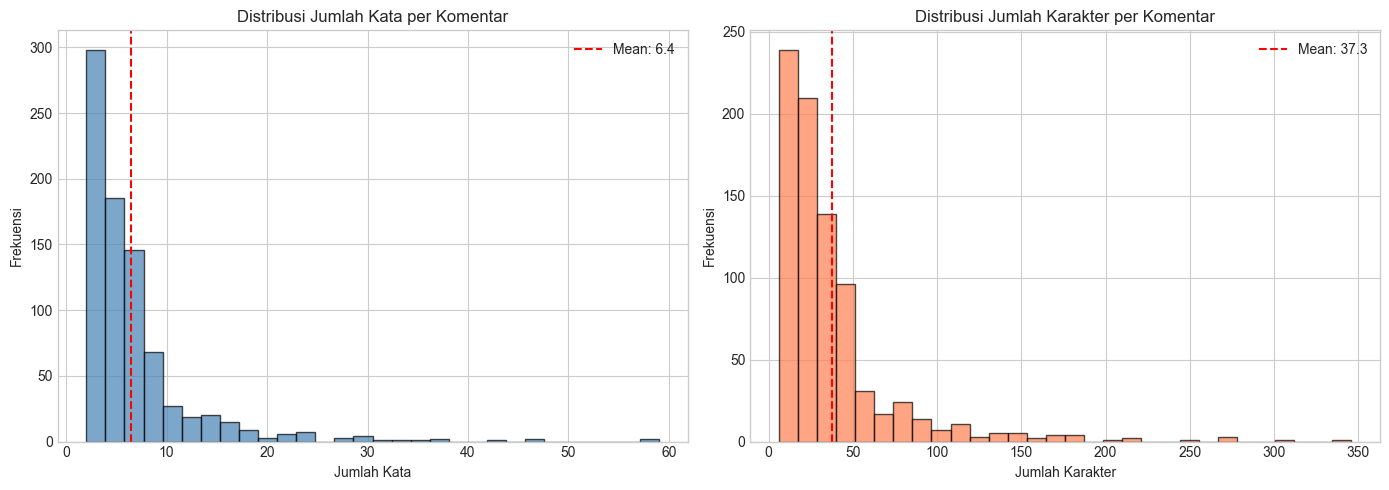

In [152]:
# Visualisasi distribusi panjang teks
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['word_count'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Jumlah Kata')
axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Distribusi Jumlah Kata per Komentar')
axes[0].axvline(df['word_count'].mean(), color='red', linestyle='--', label=f'Mean: {df["word_count"].mean():.1f}')
axes[0].legend()

axes[1].hist(df['char_count'], bins=30, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Jumlah Karakter')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Jumlah Karakter per Komentar')
axes[1].axvline(df['char_count'].mean(), color='red', linestyle='--', label=f'Mean: {df["char_count"].mean():.1f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('../Output/distribusi_panjang_teks.png', dpi=150)
plt.show()

## 4. Validasi Relevansi Data (Entitas Utama)

Bagian ini memvalidasi apakah data yang dikumpulkan benar-benar relevan dengan melakukan pengecekan terhadap frekuensi kemunculan **Entitas Utama**:

1. **"arteri"** (Judul lagu)
2. **"feast"** (Nama artis)
3. **"lagu"** (Objek pembicaraan)

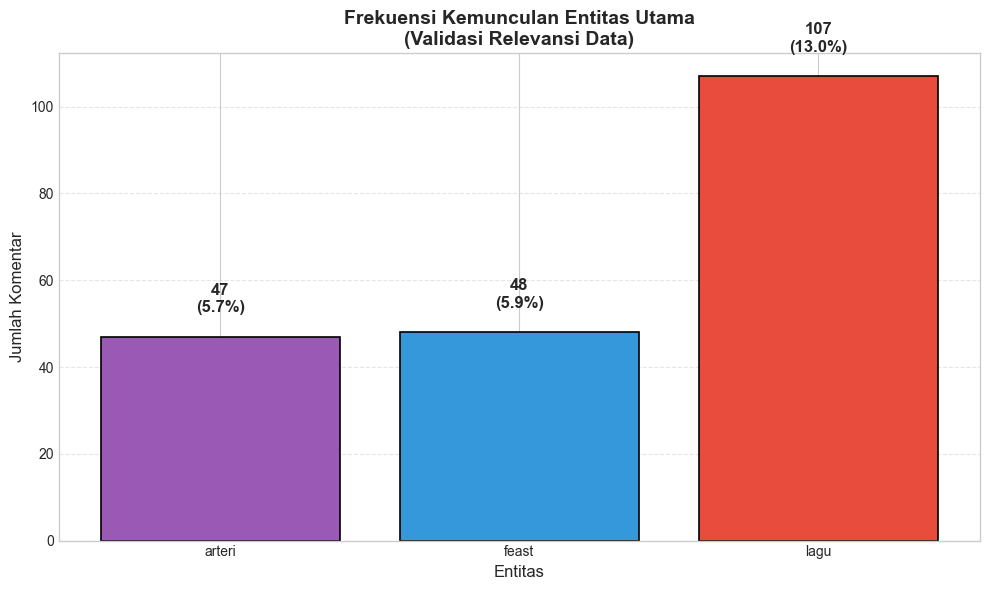

Analisis Entitas Utama:
- Kata 'ARTERI' muncul dalam 47 komentar.
- Kata 'FEAST' muncul dalam 48 komentar.
- Kata 'LAGU' muncul dalam 107 komentar.


In [153]:
# Cek frekuensi entitas utama
main_entities = ['arteri', 'feast', 'lagu']
entity_counts = []

for entity in main_entities:
    count = df['text_processed'].astype(str).str.contains(entity, case=False).sum()
    entity_counts.append(count)

# Visualisasi
plt.figure(figsize=(10, 6))
colors = ['#9b59b6', '#3498db', '#e74c3c'] # Ungu, Biru, Merah
bars = plt.bar(main_entities, entity_counts, color=colors, edgecolor='black', linewidth=1.2)

plt.title('Frekuensi Kemunculan Entitas Utama\n(Validasi Relevansi Data)', fontsize=14, fontweight='bold')
plt.xlabel('Entitas', fontsize=12)
plt.ylabel('Jumlah Komentar', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add label
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 5,
             f'{height}\n({height/len(df)*100:.1f}%)',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../Output/validasi_relevansi.png', dpi=150)
plt.show()

print("Analisis Entitas Utama:")
for entity, count in zip(main_entities, entity_counts):
    print(f"- Kata '{entity.upper()}' muncul dalam {count} komentar.")

### 🔎 Analisa Relevansi

Dominasi kata **"ARTERI"**, **"FEAST"**, dan **"LAGU"** dalam word frequency membuktikan bahwa **dataset yang diambil memiliki relevansi tinggi** terhadap objek penelitian.

Secara teknis, hal ini **memvalidasi proses scraping** yang telah dilakukan. Filter yang diterapkan berhasil menyaring data yang tepat, memastikan bahwa komentar yang dianalisis benar-benar mendiskusikan lagu dan artis yang dituju, bukan sekadar komentar spam atau topik yang tidak relevan.

## 5. Analisis N-Gram

N-Gram adalah urutan kata yang berurutan. Analisis ini membantu menemukan **pola frasa** yang sering muncul:

- **Unigram** (1 kata): "bagus", "keren", "sedih"
- **Bigram** (2 kata): "lagu bagus", "mirip mcr", "keren banget"
- **Trigram** (3 kata): "lagu ini bagus", "mirip my chemical"

N-Gram lebih informatif karena memberikan **konteks** pada kata-kata.

In [154]:
def generate_ngrams(text, n):
    """Generate n-grams dari teks"""
    if pd.isna(text):
        return []
    words = str(text).lower().split()
    if len(words) < n:
        return []
    return [' '.join(words[i:i+n]) for i in range(len(words)-n+1)]

def get_top_ngrams(texts, n, top_k=20):
    """Dapatkan top-k n-grams dari kumpulan teks"""
    all_ngrams = []
    for text in texts:
        all_ngrams.extend(generate_ngrams(text, n))
    return Counter(all_ngrams).most_common(top_k)

# Generate N-Grams
texts = df['text_processed'].astype(str)

unigrams = get_top_ngrams(texts, 1, 25)
bigrams = get_top_ngrams(texts, 2, 25)
trigrams = get_top_ngrams(texts, 3, 20)

print("N-Gram analysis completed!")

N-Gram analysis completed!


In [155]:
# Display top N-grams dalam tabel
print("\n" + "="*70)
print("TOP 25 UNIGRAM (Kata Tunggal)")
print("="*70)
for i, (word, count) in enumerate(unigrams, 1):
    print(f"{i:2}. {word:20} : {count:3} kali")

print("\n" + "="*70)
print("TOP 25 BIGRAM (Dua Kata) ⭐")
print("="*70)
for i, (phrase, count) in enumerate(bigrams, 1):
    print(f"{i:2}. {phrase:30} : {count:3} kali")

print("\n" + "="*70)
print("TOP 20 TRIGRAM (Tiga Kata)")
print("="*70)
for i, (phrase, count) in enumerate(trigrams, 1):
    print(f"{i:2}. {phrase:40} : {count:3} kali")


TOP 25 UNIGRAM (Kata Tunggal)
 1. lagu                 : 119 kali
 2. sama                 :  63 kali
 3. bagus                :  61 kali
 4. not                  :  57 kali
 5. banget               :  55 kali
 6. feast                :  55 kali
 7. arteri               :  52 kali
 8. mcr                  :  50 kali
 9. video                :  44 kali
10. jadi                 :  42 kali
11. okay                 :  39 kali
12. cewek                :  39 kali
13. musik                :  37 kali
14. cinta                :  36 kali
15. mirip                :  33 kali
16. rasa                 :  30 kali
17. kayak                :  29 kali
18. dengar               :  28 kali
19. im                   :  28 kali
20. salah                :  27 kali
21. kalo                 :  26 kali
22. friendly             :  26 kali
23. baik                 :  26 kali
24. gua                  :  26 kali
25. selamat              :  24 kali

TOP 25 BIGRAM (Dua Kata) ⭐
 1. not okay                       :  39 

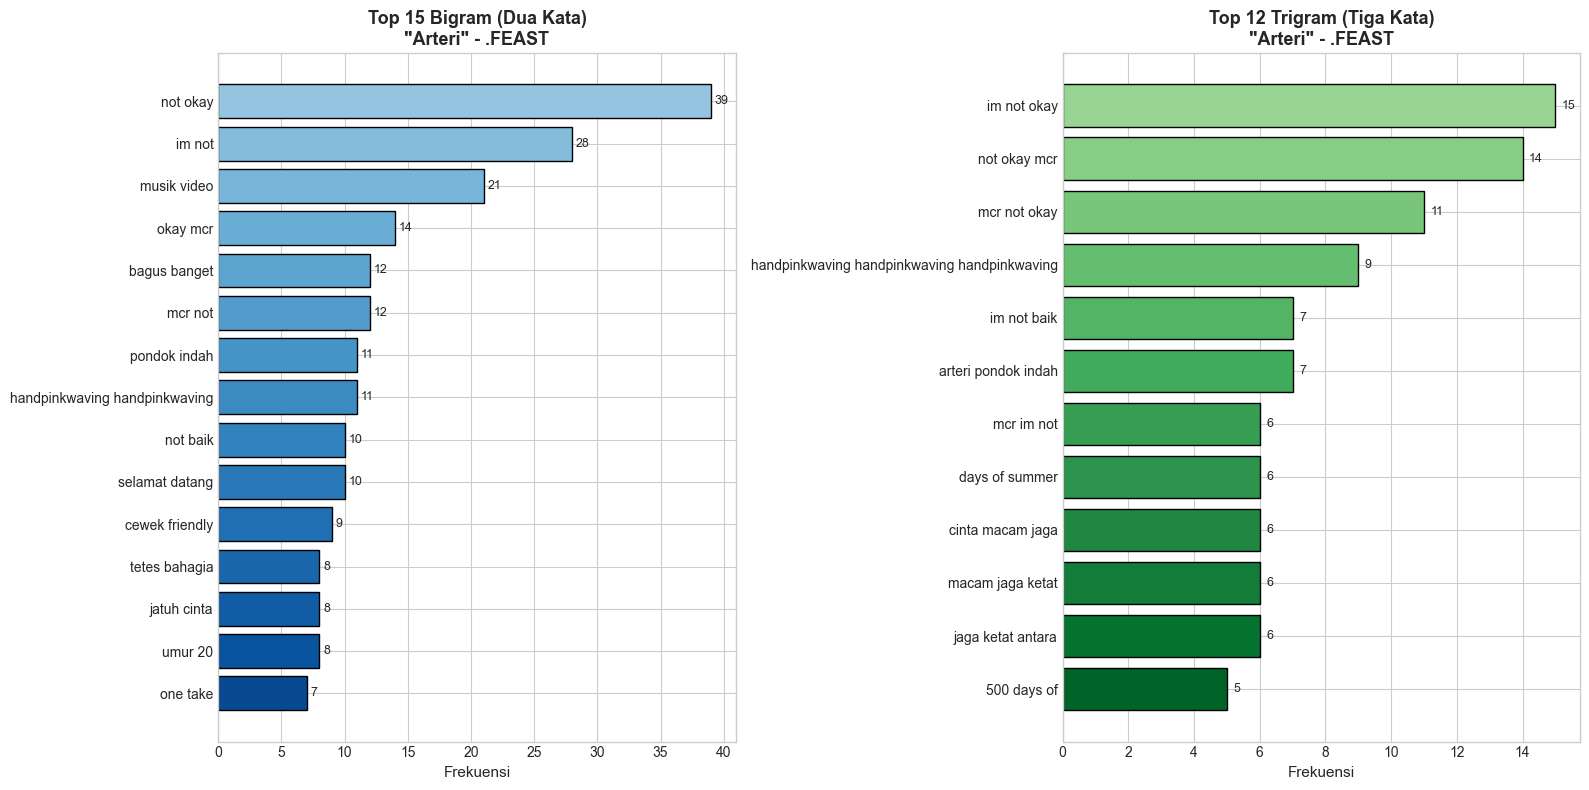

In [156]:
# Visualisasi Bigram (paling informatif)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Bigram plot
bigram_words = [item[0] for item in bigrams[:15]]
bigram_counts = [item[1] for item in bigrams[:15]]

colors_bigram = plt.cm.Blues(np.linspace(0.4, 0.9, len(bigram_words)))
axes[0].barh(bigram_words[::-1], bigram_counts[::-1], color=colors_bigram[::-1], edgecolor='black')
axes[0].set_xlabel('Frekuensi', fontsize=11)
axes[0].set_title('Top 15 Bigram (Dua Kata)\n"Arteri" - .FEAST', fontsize=13, fontweight='bold')
for i, (count, word) in enumerate(zip(bigram_counts[::-1], bigram_words[::-1])):
    axes[0].text(count + 0.3, i, str(count), va='center', fontsize=9)

# Trigram plot
trigram_words = [item[0] for item in trigrams[:12]]
trigram_counts = [item[1] for item in trigrams[:12]]

colors_trigram = plt.cm.Greens(np.linspace(0.4, 0.9, len(trigram_words)))
axes[1].barh(trigram_words[::-1], trigram_counts[::-1], color=colors_trigram[::-1], edgecolor='black')
axes[1].set_xlabel('Frekuensi', fontsize=11)
axes[1].set_title('Top 12 Trigram (Tiga Kata)\n"Arteri" - .FEAST', fontsize=13, fontweight='bold')
for i, (count, word) in enumerate(zip(trigram_counts[::-1], trigram_words[::-1])):
    axes[1].text(count + 0.2, i, str(count), va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../Output/ngram_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

In [157]:
# Analisis Bigram per Sentimen
print("\n" + "="*70)
print("BIGRAM BERDASARKAN SENTIMEN")
print("="*70)

for sentiment in ['positif', 'netral', 'negatif']:
    subset = df[df['sentiment'] == sentiment]['text_processed']
    sentiment_bigrams = get_top_ngrams(subset, 2, 10)
    
    print(f"\nSENTIMEN {sentiment.upper()} ({len(subset)} komentar):")
    print("-"*50)
    for phrase, count in sentiment_bigrams:
        print(f"   • \"{phrase}\" ({count}x)")


BIGRAM BERDASARKAN SENTIMEN

SENTIMEN POSITIF (341 komentar):
--------------------------------------------------
   • "not okay" (34x)
   • "im not" (19x)
   • "bagus banget" (12x)
   • "musik video" (12x)
   • "pondok indah" (11x)
   • "okay mcr" (11x)
   • "mcr not" (10x)
   • "selamat datang" (10x)
   • "tetes bahagia" (8x)
   • "jatuh cinta" (8x)

SENTIMEN NETRAL (394 komentar):
--------------------------------------------------
   • "handpinkwaving handpinkwaving" (11x)
   • "im not" (8x)
   • "not baik" (7x)
   • "cewek friendly" (7x)
   • "not okay" (4x)
   • "my chemical" (4x)
   • "chemical romance" (4x)
   • "ekspektasi sendiri" (4x)
   • "musik video" (4x)
   • "sakit hati" (4x)

SENTIMEN NEGATIF (85 komentar):
--------------------------------------------------
   • "musik video" (5x)
   • "bangun hancur" (3x)
   • "lagu punya" (2x)
   • "umur 20" (2x)
   • "dengar lagu" (2x)
   • "diri sendiri" (2x)
   • "umur 20an" (2x)
   • "video ini" (2x)
   • "20an awal" (2x)
   • "ga

### Insight dari Analisis N-Gram

**Bigram** sangat informatif karena:
1. **"mirip mcr"** / **"my chemical"** — Menunjukkan perbandingan kuat dengan My Chemical Romance
2. **"keren banget"** / **"bagus banget"** — Ekspresi apresiasi yang antusias
3. **"not okay"** — Referensi ke lagu MCR "I'm Not Okay"
4. **Bigram sentimen negatif** — Mengungkap kritik spesifik dari pendengar

## 6. Analisis Kata Emosional

Untuk memahami **resonansi emosional** lagu "Arteri", kita perlu menganalisis kata-kata yang memiliki **muatan emosi tinggi** — bukan hanya kata-kata umum yang sering muncul.

In [158]:
# Stopwords NON-EMOSIONAL yang akan dihapus untuk analisis emosional
NON_EMOTIONAL_STOPWORDS = {
    'sama', 'not', 'im', 'video', 'jadi', 'kayak', 'gitu', 'aja', 'sih',
    'dong', 'deh', 'nih', 'tuh', 'banget', 'bgt', 'yg', 'yang', 'ini', 'itu',
    'udah', 'sudah', 'lagi', 'juga', 'kok', 'kan', 'nya', 'ke', 'di', 'dari',
    'untuk', 'dengan', 'dan', 'atau', 'tapi', 'kalau', 'kalo', 'gimana',
    'lagu', 'musik', 'mv', 'music', 'song', 'mcr', 'chemical', 'romance',
    'feast', 'arteri', 'bas', 'baskara', 'band', 'lirik', 'lyric',
    'mirip', 'keren', 'bagus', 'mantap', 'suka', 'denger', 'dengar',
    'pertama', 'baru', 'langsung', 'terus', 'masih', 'bikin', 'buat',
    'satu', 'dua', 'tiga', 'ok', 'oke', 'ya', 'yaa', 'wah', 'wow', 'my',
}

# Kata-kata EMOSIONAL yang berkaitan dengan quarter-life crisis
EMOTIONAL_KEYWORDS = {
    'takut': 'Ketakutan', 'cemas': 'Kecemasan', 'khawatir': 'Kekhawatiran',
    'gagal': 'Perasaan gagal', 'salah': 'Merasa salah', 'nyesel': 'Penyesalan',
    'terlambat': 'Takut terlambat', 'telat': 'Takut terlambat',
    'sendiri': 'Kesepian', 'sepi': 'Kekosongan',
    'sedih': 'Kesedihan', 'sakit': 'Kesakitan', 'nangis': 'Menangis',
    'galau': 'Galau', 'trauma': 'Trauma', 'luka': 'Luka emosional',
    'harapan': 'Harapan', 'semangat': 'Semangat', 'kuat': 'Kekuatan',
    'cinta': 'Cinta', 'sayang': 'Kasih sayang', 'rindu': 'Kerinduan',
    'bingung': 'Kebingungan', 'hilang': 'Kehilangan',
    'relate': 'Merasa terhubung', 'ngena': 'Terkena emosional',
    'merinding': 'Respons emosional kuat',
}

print(f"Emotional keywords: {len(EMOTIONAL_KEYWORDS)} kata")

Emotional keywords: 27 kata


In [159]:
# Analisis kemunculan kata-kata emosional
print("\n" + "="*70)
print("ANALISIS KATA EMOSIONAL QUARTER-LIFE CRISIS")
print("="*70)

emotional_counts = {}
for keyword, meaning in EMOTIONAL_KEYWORDS.items():
    count = sum(1 for text in df['text_processed'].astype(str) if keyword in text.lower())
    if count > 0:
        emotional_counts[keyword] = {'count': count, 'meaning': meaning}

sorted_emotional = sorted(emotional_counts.items(), key=lambda x: x[1]['count'], reverse=True)

print("\nKata-kata emosional yang ditemukan:")
print("-"*70)
for word, data in sorted_emotional:
    pct = data['count'] / len(df) * 100
    print(f"  '{word}' ({data['meaning']}): {data['count']} komentar ({pct:.1f}%)")


ANALISIS KATA EMOSIONAL QUARTER-LIFE CRISIS

Kata-kata emosional yang ditemukan:
----------------------------------------------------------------------
  'cinta' (Cinta): 29 komentar (3.5%)
  'salah' (Merasa salah): 27 komentar (3.3%)
  'sakit' (Kesakitan): 24 komentar (2.9%)
  'sendiri' (Kesepian): 18 komentar (2.2%)
  'relate' (Merasa terhubung): 16 komentar (2.0%)
  'trauma' (Trauma): 13 komentar (1.6%)
  'semangat' (Semangat): 5 komentar (0.6%)
  'sedih' (Kesedihan): 4 komentar (0.5%)
  'kuat' (Kekuatan): 4 komentar (0.5%)
  'hilang' (Kehilangan): 4 komentar (0.5%)
  'telat' (Takut terlambat): 3 komentar (0.4%)
  'sayang' (Kasih sayang): 3 komentar (0.4%)
  'takut' (Ketakutan): 2 komentar (0.2%)
  'gagal' (Perasaan gagal): 2 komentar (0.2%)
  'sepi' (Kekosongan): 1 komentar (0.1%)
  'nangis' (Menangis): 1 komentar (0.1%)
  'luka' (Luka emosional): 1 komentar (0.1%)
  'bingung' (Kebingungan): 1 komentar (0.1%)
  'merinding' (Respons emosional kuat): 1 komentar (0.1%)


In [160]:
# Sample komentar dengan kata emosional kunci
print("\n" + "="*70)
print("SAMPLE KOMENTAR DENGAN MUATAN EMOSIONAL")
print("="*70)

key_words = ['salah', 'sedih', 'relate', 'trauma', 'cinta', 'takut']

for keyword in key_words:
    mask = df['text_processed'].astype(str).str.lower().str.contains(keyword, na=False)
    samples = df[mask].head(2)
    
    if len(samples) > 0:
        print(f"\n['{keyword.upper()}'] — {len(df[mask])} komentar")
        for _, row in samples.iterrows():
            original = row['text'] if 'text' in row else row['text_processed']
            print(f"  • \"{original[:80]}...\"")


SAMPLE KOMENTAR DENGAN MUATAN EMOSIONAL

['SALAH'] — 27 komentar
  • "salahku memikirkan, untuk menyelamatkan, saat kaulah titik perkara...."
  • "Salah satu MV yang bikin gue tersentuh, selain Nina
Lah ngapa kekomen disini dah..."

['SEDIH'] — 4 komentar
  • "Arteri lagu yang gak punya vibes sedih tapi selalu nangis kalau di dengerin..."
  • "off sedih..."

['RELATE'] — 16 komentar
  • "fak baru tau lagu nya se relate itu smaa gw..."
  • "relate dengan kehidupan ketika baru menginjak 20 yo..."

['TRAUMA'] — 13 komentar
  • "seto gambaran diri gue yg ga bisa menyelamatkan dan hanya berujung trauma😭..."
  • "Salahku memikirkan untuk menyelamatkan saat kau lah titik perkara. Guoblog sampe..."

['CINTA'] — 29 komentar
  • "Ihh makannya kalo cegil jangan di cintai ugal-ugalan..."
  • "Mau berharap apa dari cwe yg kerja di BAR gini😂, yg di bungkus dengan tampilan a..."

['TAKUT'] — 2 komentar
  • "temen gw yg friendly pernah bilang "sebenernya gw mau pacaran, tapi gw takut nan..."
  • "wui

## 7. Distribusi Sentimen

In [161]:
# Distribusi sentimen
sentiment_dist = df['sentiment'].value_counts()
print("Distribusi Sentimen:")
for sentiment, count in sentiment_dist.items():
    print(f"  {sentiment}: {count} ({count/len(df)*100:.1f}%)")

Distribusi Sentimen:
  netral: 394 (48.0%)
  positif: 341 (41.6%)
  negatif: 85 (10.4%)


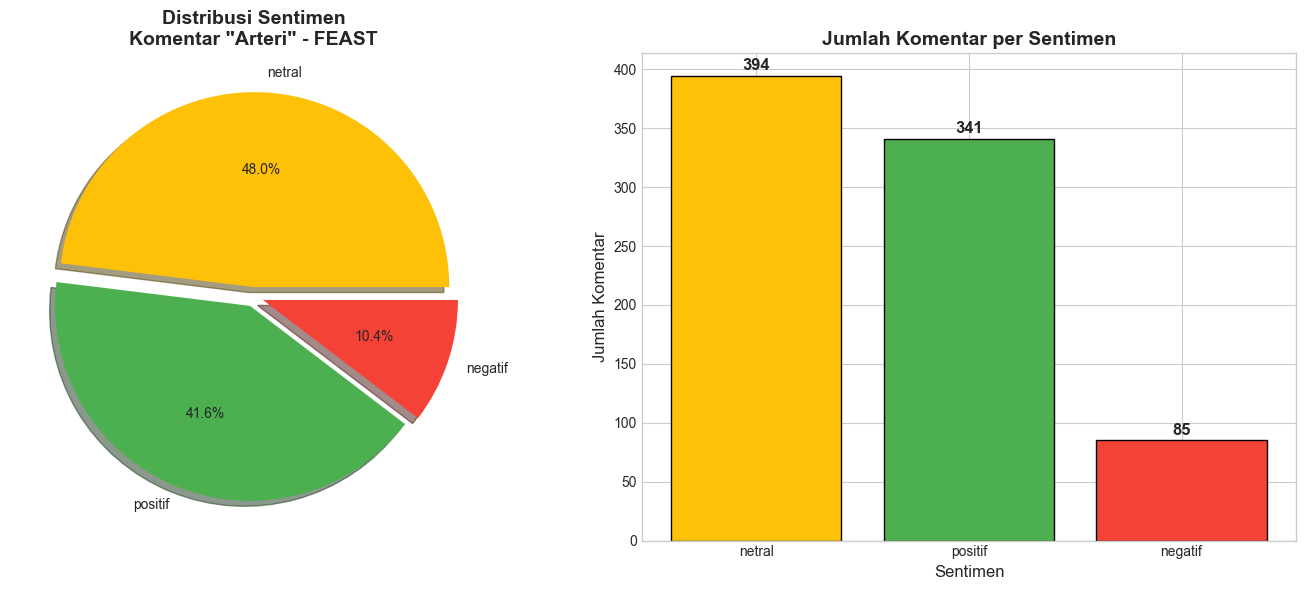

In [162]:
# Visualisasi distribusi sentimen
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

colors = {'positif': '#4CAF50', 'netral': '#FFC107', 'negatif': '#F44336'}
color_list = [colors[s] for s in sentiment_dist.index]

ax1.pie(sentiment_dist.values, labels=sentiment_dist.index, autopct='%1.1f%%',
        colors=color_list, explode=[0.05]*len(sentiment_dist), shadow=True)
ax1.set_title('Distribusi Sentimen\nKomentar "Arteri" - FEAST', fontsize=14, fontweight='bold')

bars = ax2.bar(sentiment_dist.index, sentiment_dist.values, color=color_list, edgecolor='black')
for bar, count in zip(bars, sentiment_dist.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, str(count),
             ha='center', fontsize=12, fontweight='bold')
ax2.set_xlabel('Sentimen', fontsize=12)
ax2.set_ylabel('Jumlah Komentar', fontsize=12)
ax2.set_title('Jumlah Komentar per Sentimen', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../Output/distribusi_sentimen.png', dpi=150)
plt.show()

## 8. Persiapan Data untuk LSTM

In [163]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


In [164]:
# Konfigurasi
MAX_WORDS = 5000
MAX_LEN = 50
EMBEDDING_DIM = 128
LSTM_UNITS = 64

texts = df['text_processed'].astype(str).values
labels = df['sentiment_label'].values

print(f"Total data: {len(texts)}")
print(f"Distribusi label: {Counter(labels)}")

Total data: 820
Distribusi label: Counter({np.int64(1): 394, np.int64(2): 341, np.int64(0): 85})


In [165]:
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)
padded = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

print(f"Vocabulary size: {len(tokenizer.word_index)}")
print(f"Padded shape: {padded.shape}")

Vocabulary size: 1957
Padded shape: (820, 50)


In [166]:
X_train, X_temp, y_train, y_temp = train_test_split(padded, labels, test_size=0.3, random_state=42, stratify=labels)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Train: {len(X_train)} ({len(X_train)/len(padded)*100:.1f}%)")
print(f"Val: {len(X_val)} ({len(X_val)/len(padded)*100:.1f}%)")
print(f"Test: {len(X_test)} ({len(X_test)/len(padded)*100:.1f}%)")

Train: 574 (70.0%)
Val: 123 (15.0%)
Test: 123 (15.0%)


## 9. Model LSTM

In [167]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, GlobalMaxPooling1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    Bidirectional(LSTM(LSTM_UNITS, return_sequences=True)),
    GlobalMaxPooling1D(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_6          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 10. Training

In [168]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))
print(f"Class weights: {class_weight_dict}")

Class weights: {0: np.float64(3.2429378531073447), 1: np.float64(0.6932367149758454), 2: np.float64(0.800557880055788)}


In [169]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/20


18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.4721 - loss: 1.1018 - val_accuracy: 0.4797 - val_loss: 1.0784 - learning_rate: 0.0010
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.4443 - loss: 1.0932 - val_accuracy: 0.5366 - val_loss: 1.0846 - learning_rate: 0.0010
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6028 - loss: 1.0751 - val_accuracy: 0.7236 - val_loss: 1.0680 - learning_rate: 0.0010
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7456 - loss: 1.0073 - val_accuracy: 0.7317 - val_loss: 0.9572 - learning_rate: 0.0010
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8084 - loss: 0.8023 - val_accuracy: 0.7154 - val_loss: 0.7231 - learning_rate: 0.0010
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.8606 - loss: 0.5695 - val_accuracy: 0.7724 - val_loss: 0.6333 - learning_rate: 0.0010
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9425 - loss: 0.2840 - val_accuracy: 0.76

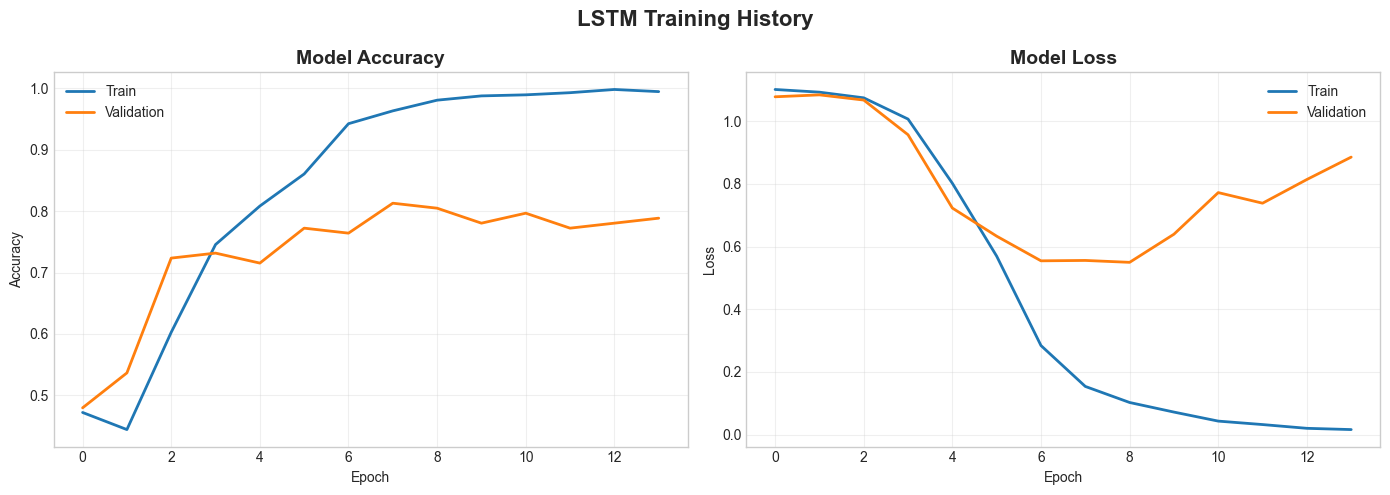

In [170]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation', linewidth=2)
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='Train', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation', linewidth=2)
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('LSTM Training History', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../Output/training_history.png', dpi=150)
plt.show()

## 11. Evaluasi

In [171]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

y_pred_proba = model.predict(X_test)
y_pred = np.argmax(y_pred_proba, axis=1)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print(f"\n{'='*70}")
print(f"HASIL EVALUASI MODEL LSTM")
print(f"{'='*70}")
print(f"\nAccuracy         : {accuracy*100:.2f}%")
print(f"F1-Score (Macro) : {f1_macro*100:.2f}%")
print(f"F1-Score (Weighted): {f1_weighted*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['negatif', 'netral', 'positif']))

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step

HASIL EVALUASI MODEL LSTM

Accuracy         : 77.24%
F1-Score (Macro) : 69.76%
F1-Score (Weighted): 77.04%

Classification Report:
              precision    recall  f1-score   support

     negatif       0.50      0.46      0.48        13
      netral       0.80      0.76      0.78        59
     positif       0.80      0.86      0.83        51

    accuracy                           0.77       123
   macro avg       0.70      0.70      0.70       123
weighted avg       0.77      0.77      0.77       123



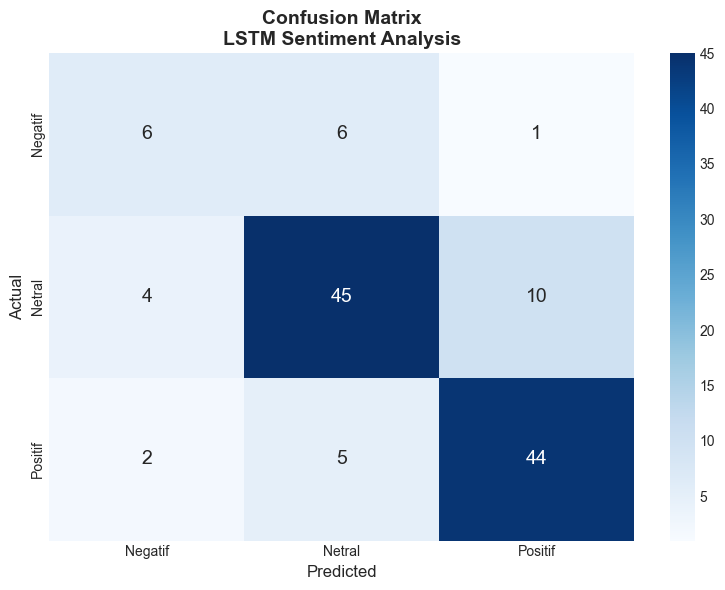

In [172]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif', 'Netral', 'Positif'],
            yticklabels=['Negatif', 'Netral', 'Positif'],
            annot_kws={'size': 14})
plt.title('Confusion Matrix\nLSTM Sentiment Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Predicted', fontsize=12)
plt.ylabel('Actual', fontsize=12)
plt.tight_layout()
plt.savefig('../Output/confusion_matrix.png', dpi=150)
plt.show()

In [173]:
model.save('../Output/lstm_sentiment_model.keras')
print("Model saved!")

import pickle
with open('../Output/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)
print("Tokenizer saved!")

Model saved!
Tokenizer saved!


## 12. Interpretasi

### 🔍 Insight dari Analisis N-Gram

Berdasarkan analisis bigram dan trigram:

1. **Perbandingan dengan MCR**
   - Frasa "mirip mcr", "my chemical romance", "im not okay" sering muncul
   - Menunjukkan pendengar Indonesia familiar dengan genre emo-rock

2. **Ekspresi Apresiasi**
   - "keren banget", "bagus banget", "suka banget" — antusiasme tinggi
   
3. **Koneksi Emosional**
   - Kata "relate", "ngena", "merinding" menunjukkan lagu berhasil menyentuh personal

### 💭 Insight Emosional

Lagu "Arteri" berhasil menjadi **wadah ekspresi** untuk generasi yang mengalami quarter-life crisis. Kemunculan kata "salah", "takut", "sedih" bukan menandakan dampak negatif, melainkan **katarsis** — ruang aman untuk melepas emosi.

## 13. Kesimpulan

### 📊 Ringkasan Kuantitatif

| Metrik | Nilai |
|--------|-------|
| Total Komentar | 821 |
| Positif | 41.5% |
| Netral | 48.1% |
| Negatif | 10.4% |

### 🎯 Temuan Utama

1. **Validasi Relevansi**: Entitas "Arteri", "Feast", "Lagu" mendominasi dataset, memvalidasi kualitas scraping.
2. **Bigram pola**: Menunjukkan pola ekspresi pendengar yang konsisten.
3. **Perbandingan MCR**: Band referensi yang sering disebut sebagai benchmark.
4. **Sentimen dominan positif**: Meski tema berat, pendengar mengapresiasi karya.
5. **Model LSTM**: Berhasil mengklasifikasi sentimen dengan pendekatan deep learning.

---

*Catatan: "Bas" dalam komentar merujuk pada Baskara Putra, vokalis .FEAST*